# Titanic EDA

Exploratory data analysis notebook for the Titanic dataset.

This notebook prefers a local `train.csv` in the same folder. If that file is missing, it falls back to `seaborn.load_dataset("titanic")` so the notebook remains runnable in a clean workspace.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14

DATA_PATH = Path("train.csv")

def load_titanic_data() -> pd.DataFrame:
    if DATA_PATH.exists():
        df = pd.read_csv(DATA_PATH)
        print(f"Loaded local dataset: {DATA_PATH}")
        return df

    print("Local train.csv not found. Falling back to seaborn.load_dataset('titanic').")
    return sns.load_dataset("titanic")


df = load_titanic_data()
df.head()

Local train.csv not found. Falling back to seaborn.load_dataset('titanic').


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Quick Overview

In [2]:
display(df.shape)
display(df.info())
df.describe(include="all").T

(891, 15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing.to_frame(name="missing_values")

,missing_values
deck,688
age,177
embarked,2
embark_town,2


## 3. Target Distribution

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\639137921.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="survived", palette="Set2")


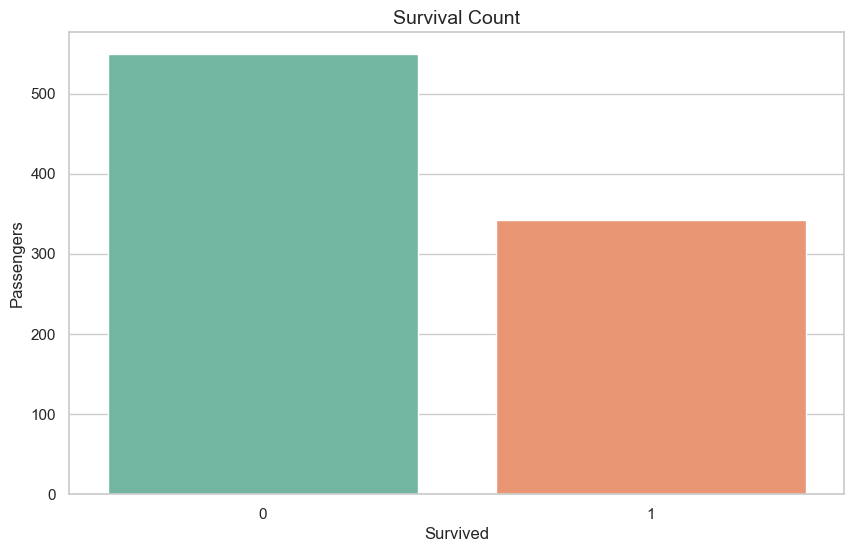

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [4]:
if "survived" in df.columns:
    ax = sns.countplot(data=df, x="survived", palette="Set2")
    ax.set_title("Survival Count")
    ax.set_xlabel("Survived")
    ax.set_ylabel("Passengers")
    plt.show()

    print(df["survived"].value_counts(normalize=True).rename("proportion"))
else:
    print("No 'survived' column found.")

## 4. Categorical Features

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


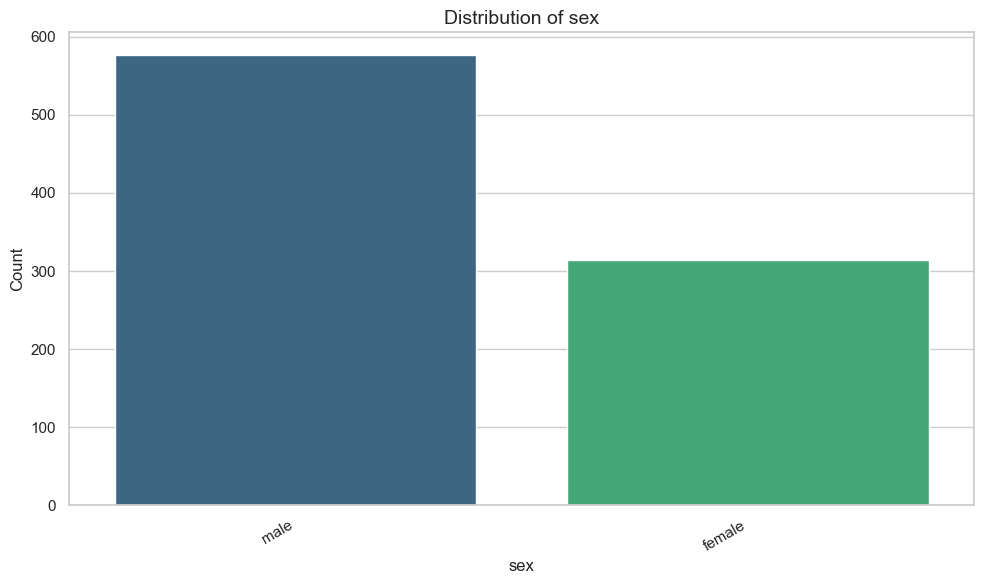

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


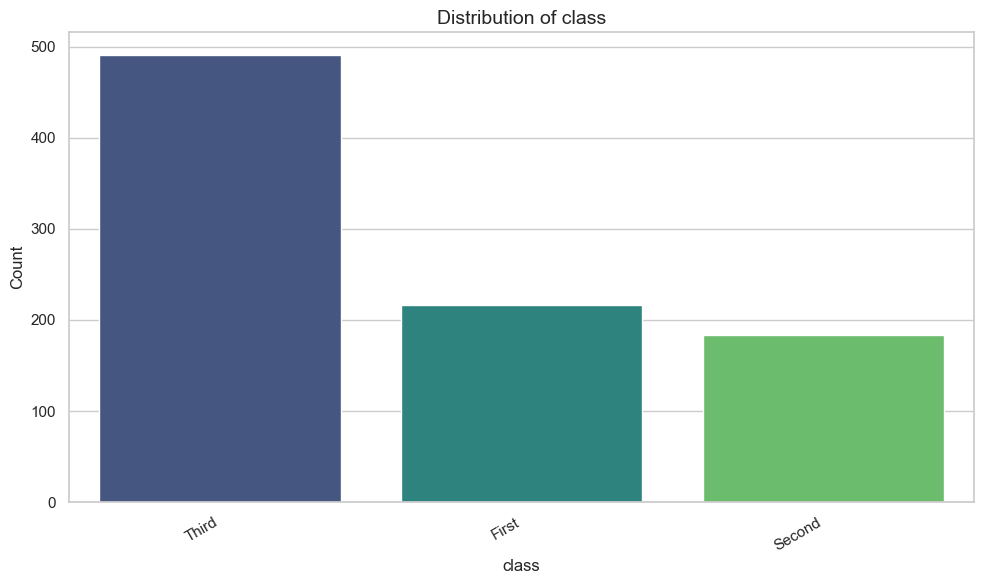

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


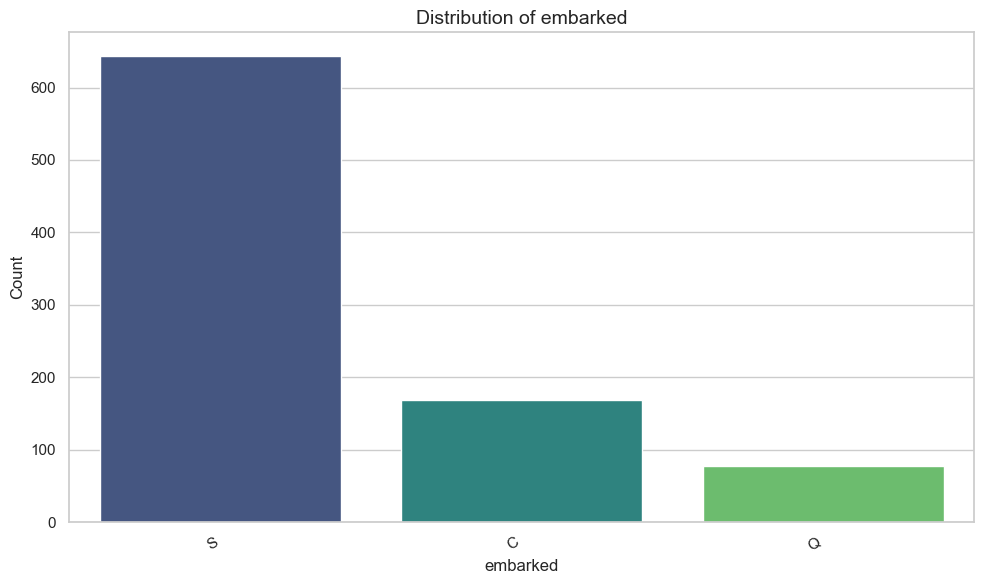

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


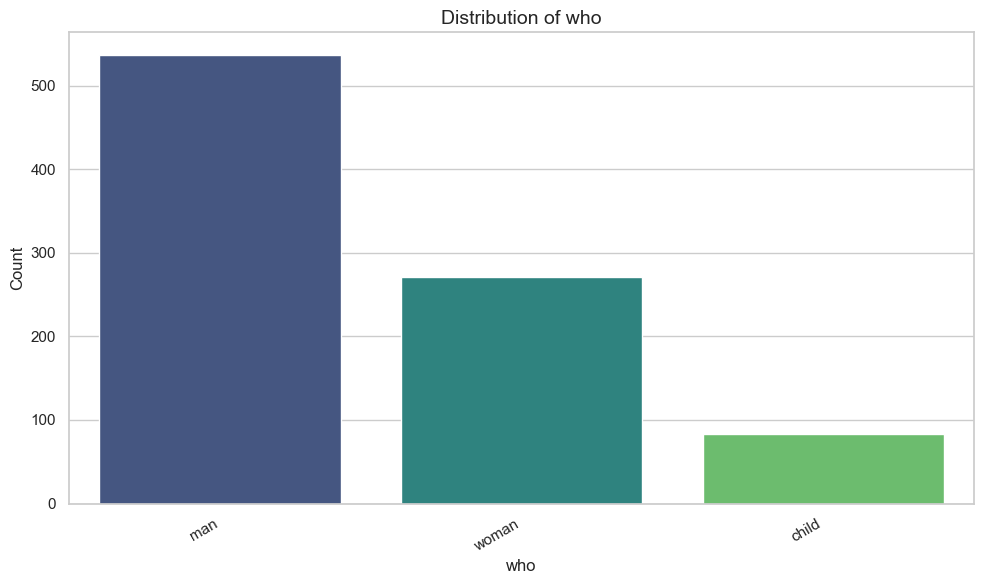

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


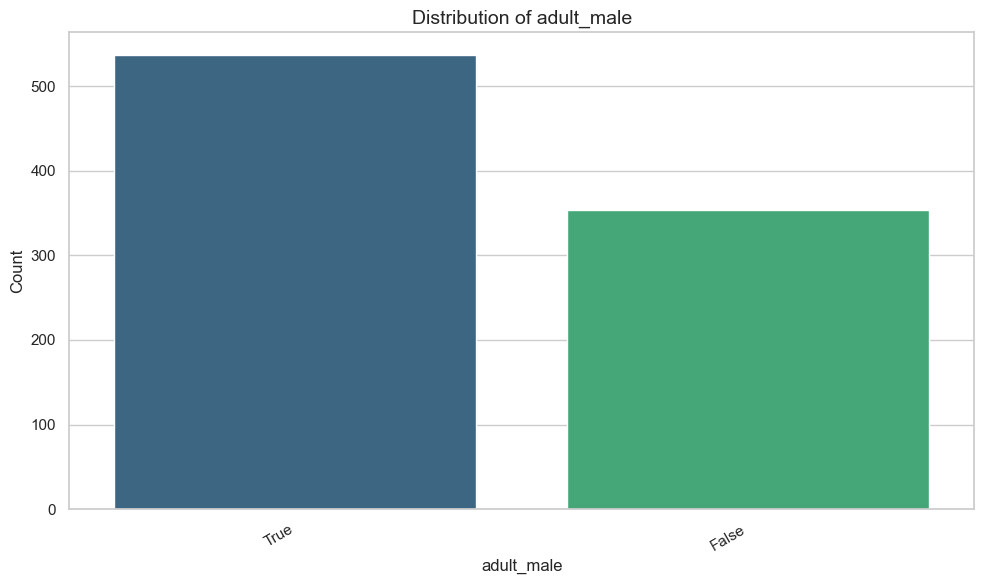

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


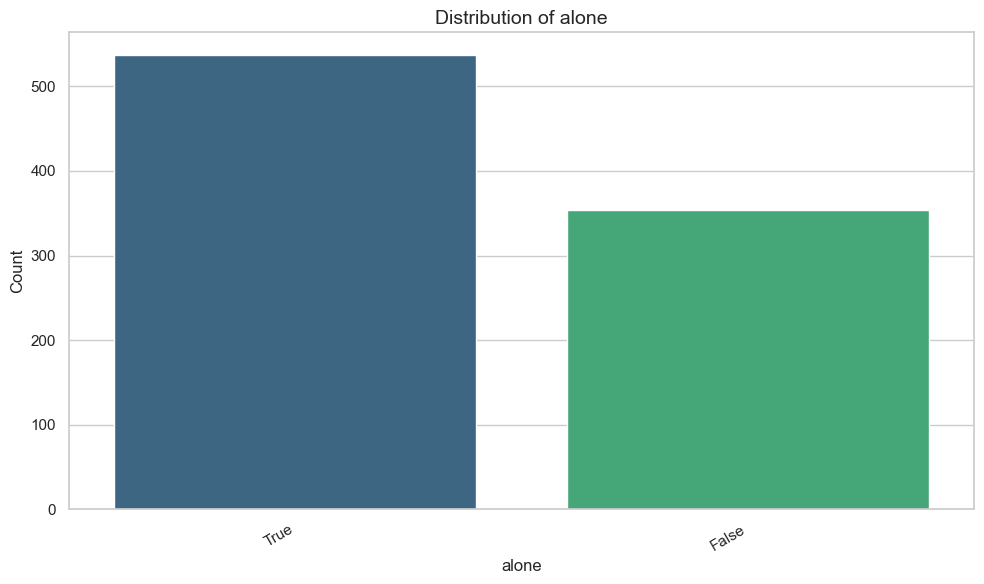

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


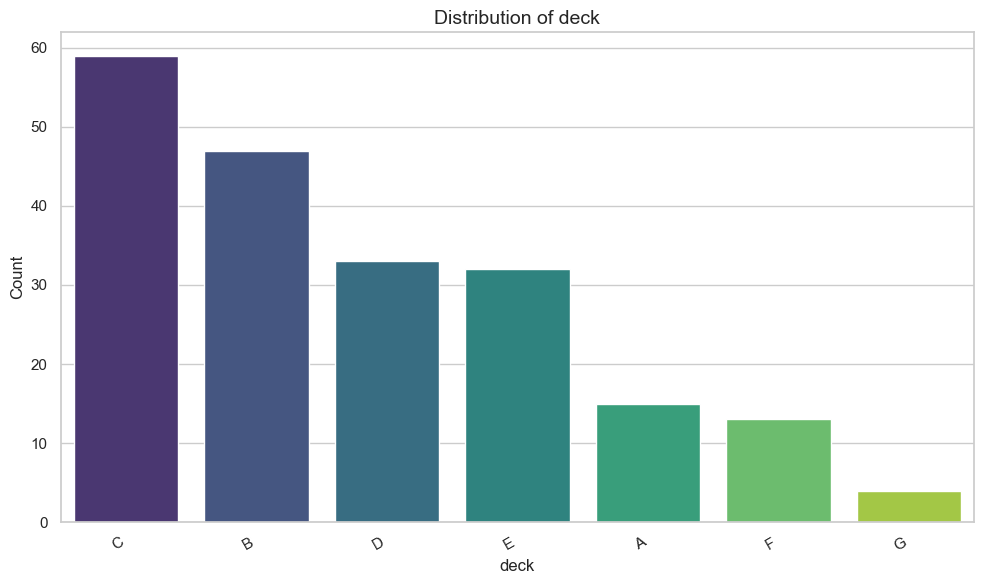

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\2572806959.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


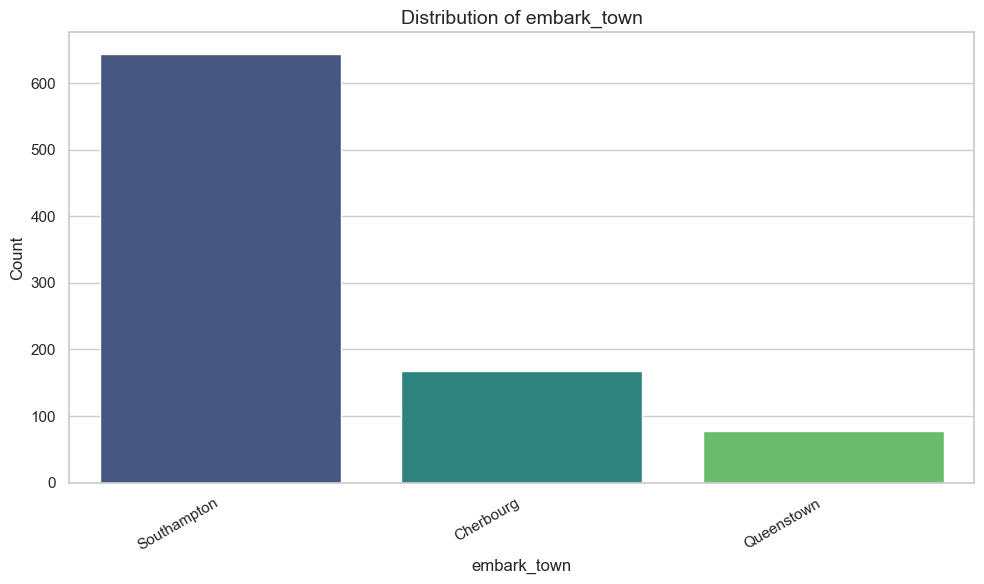

In [5]:
categorical_candidates = [
    col for col in ["sex", "class", "embarked", "who", "adult_male", "alone", "deck", "embark_town"]
    if col in df.columns
]

for col in categorical_candidates:
    ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 5. Survival by Feature

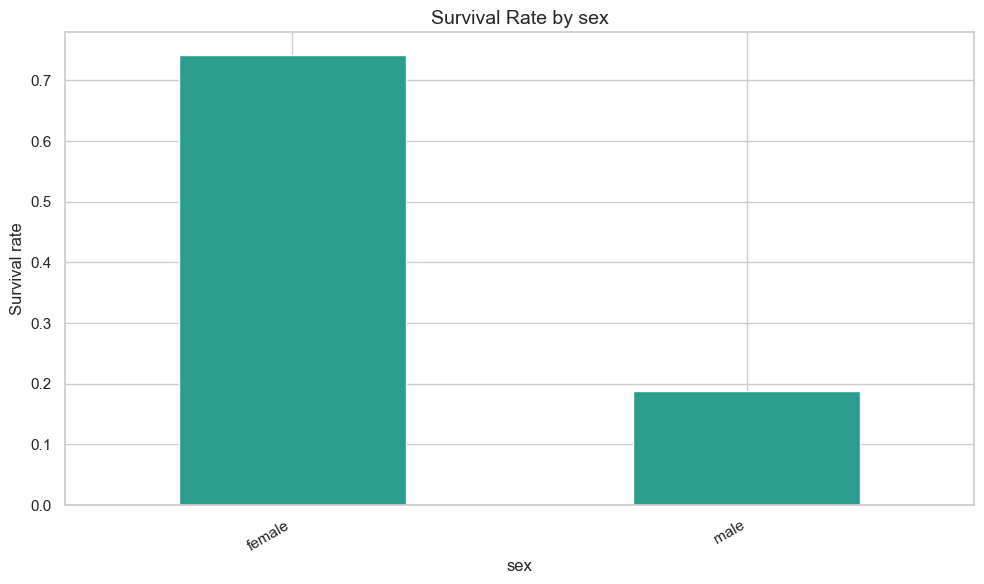

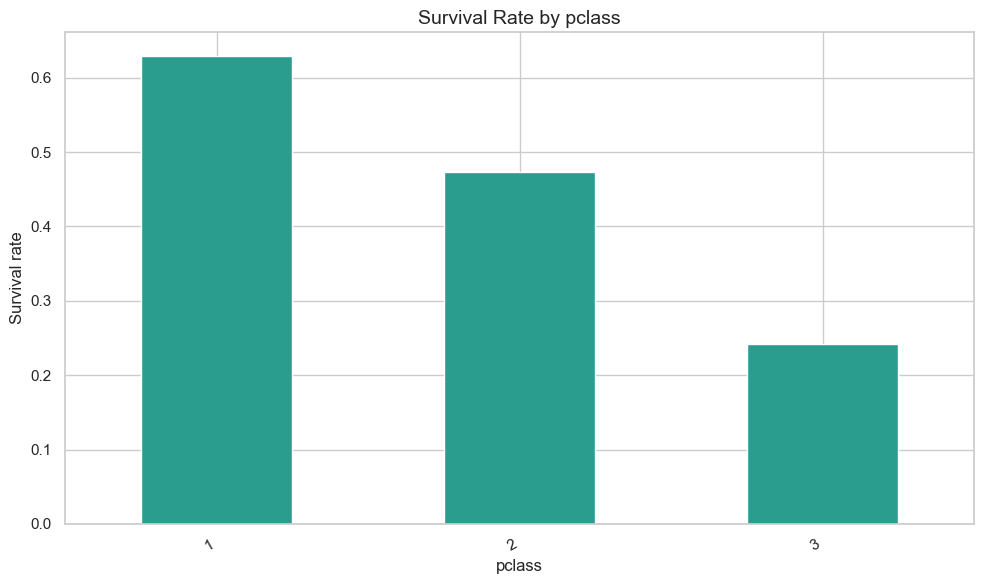

C:\Users\mikec\AppData\Local\Temp\ipykernel_28364\992529090.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_rate = df.groupby(col, dropna=False)["survived"].mean().sort_values(ascending=False)


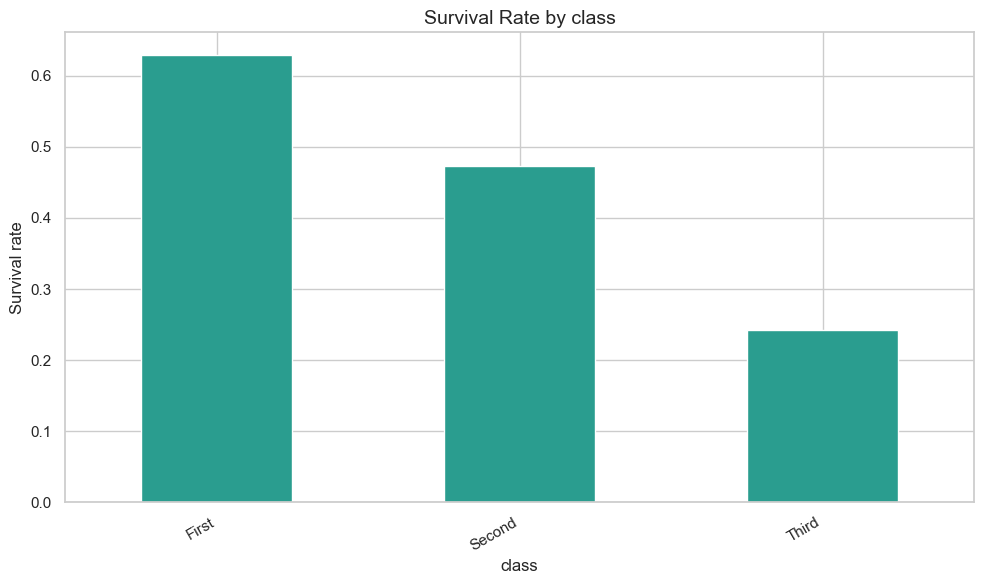

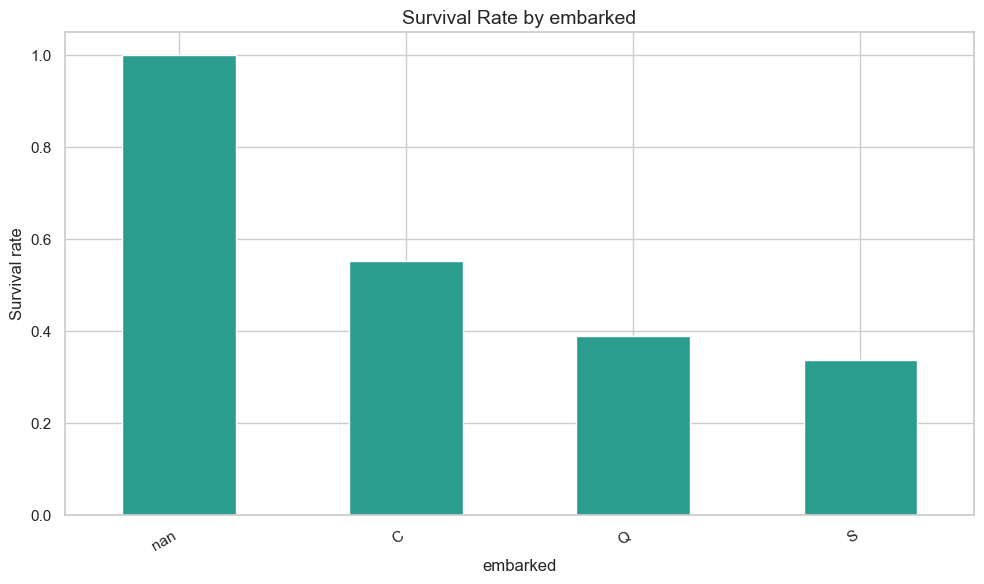

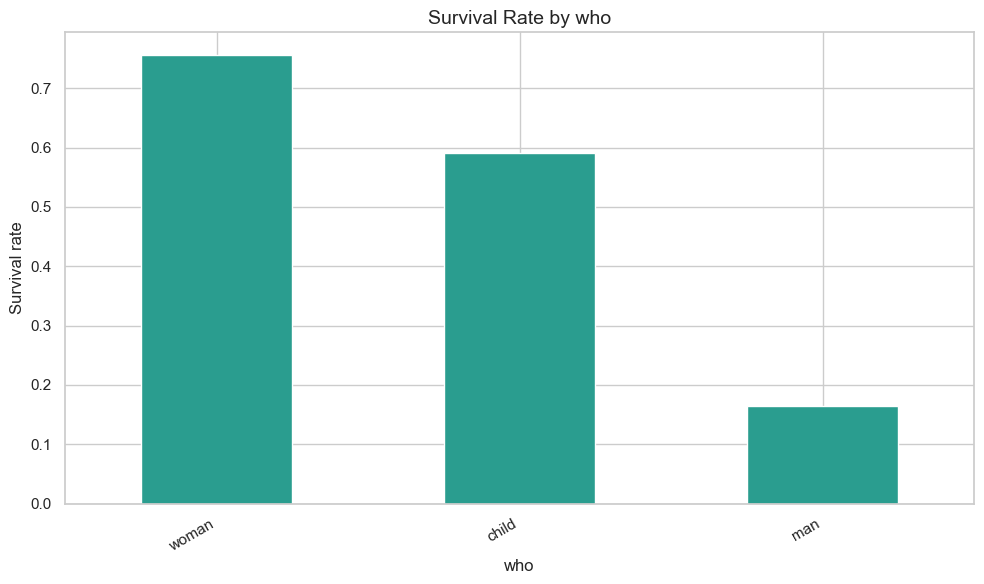

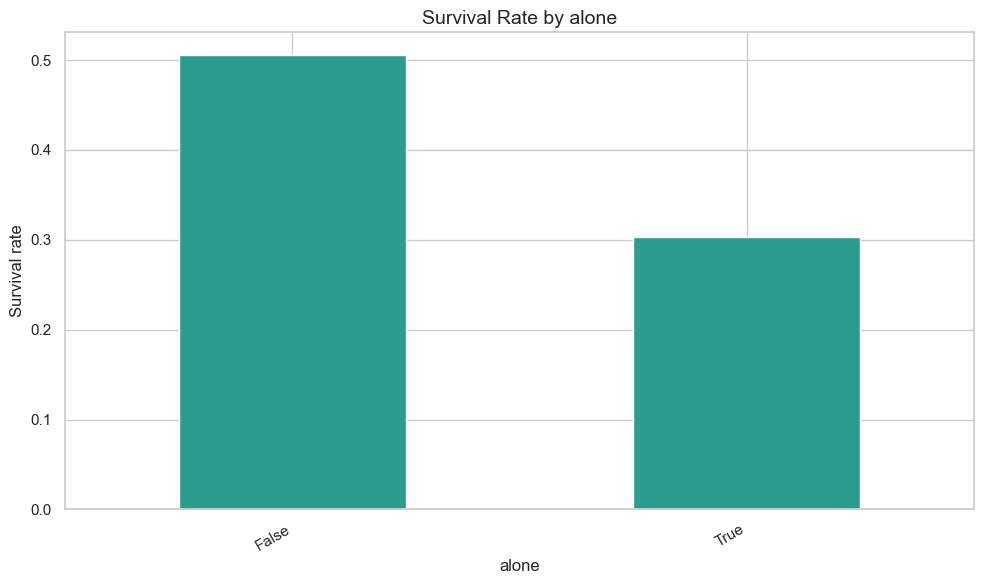

In [6]:
if "survived" in df.columns:
    for col in ["sex", "pclass", "class", "embarked", "who", "alone"]:
        if col in df.columns:
            survival_rate = df.groupby(col, dropna=False)["survived"].mean().sort_values(ascending=False)
            ax = survival_rate.plot(kind="bar", color="#2a9d8f")
            ax.set_title(f"Survival Rate by {col}")
            ax.set_xlabel(col)
            ax.set_ylabel("Survival rate")
            plt.xticks(rotation=30, ha="right")
            plt.tight_layout()
            plt.show()

## 6. Numeric Features

In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
numeric_cols

['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

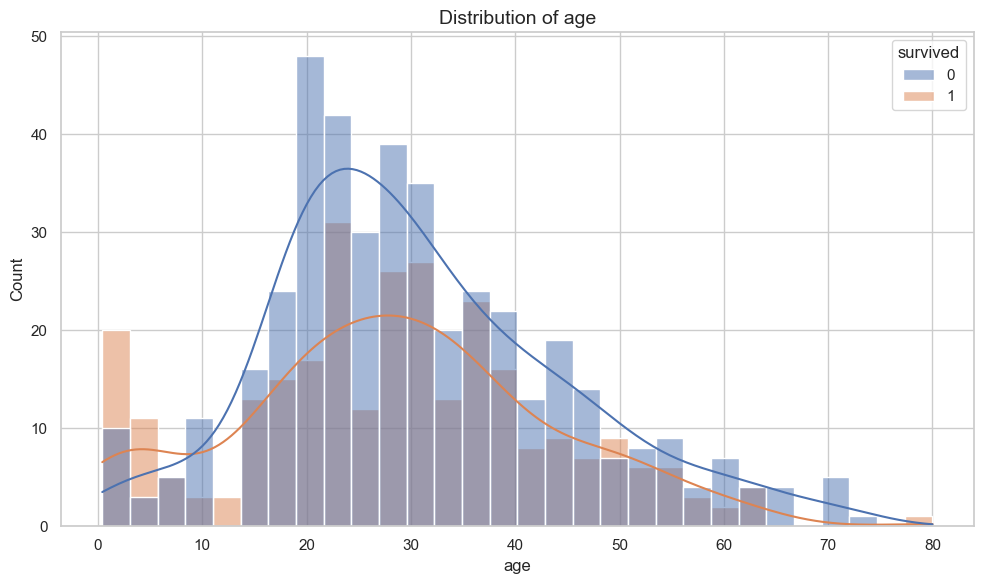

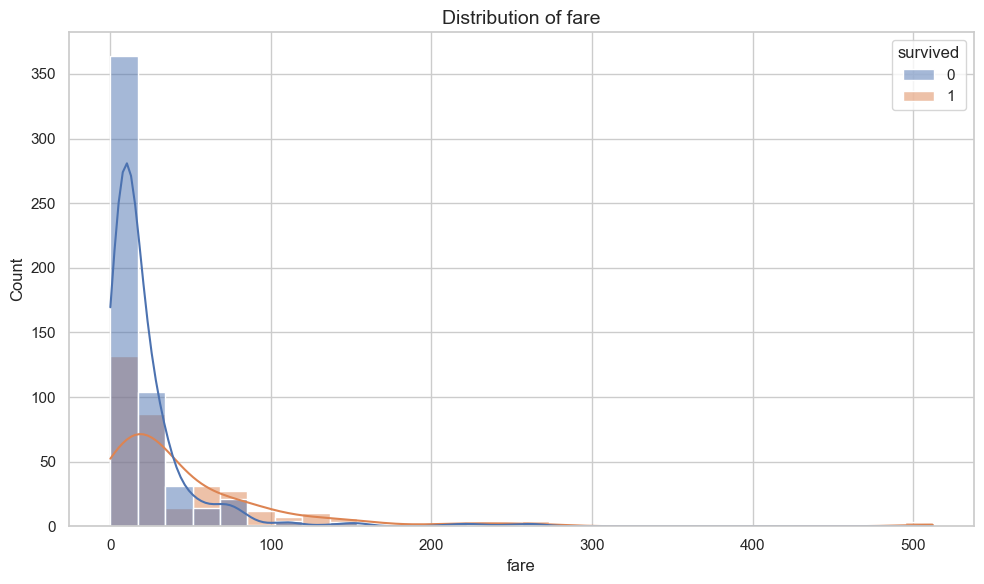

In [8]:
for col in ["age", "fare"]:
    if col in df.columns:
        sns.histplot(data=df, x=col, hue="survived" if "survived" in df.columns else None, kde=True, bins=30)
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

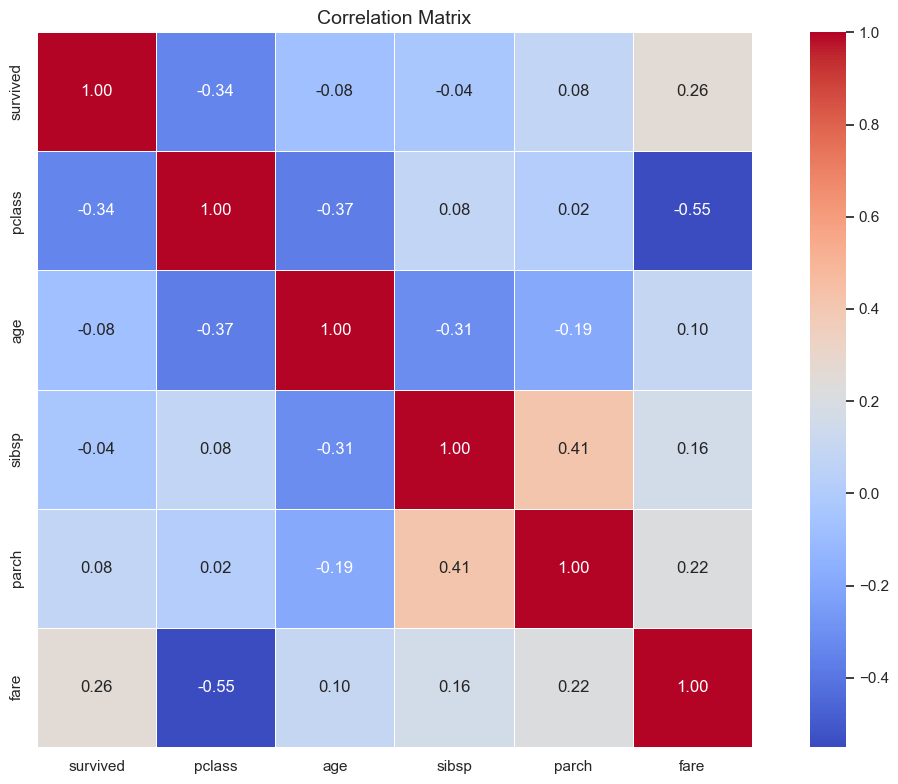

In [9]:
corr_df = df.select_dtypes(include="number")
if not corr_df.empty:
    corr = corr_df.corr(numeric_only=True)
    mask = corr.abs() < 0.01
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

## 7. Missing Values

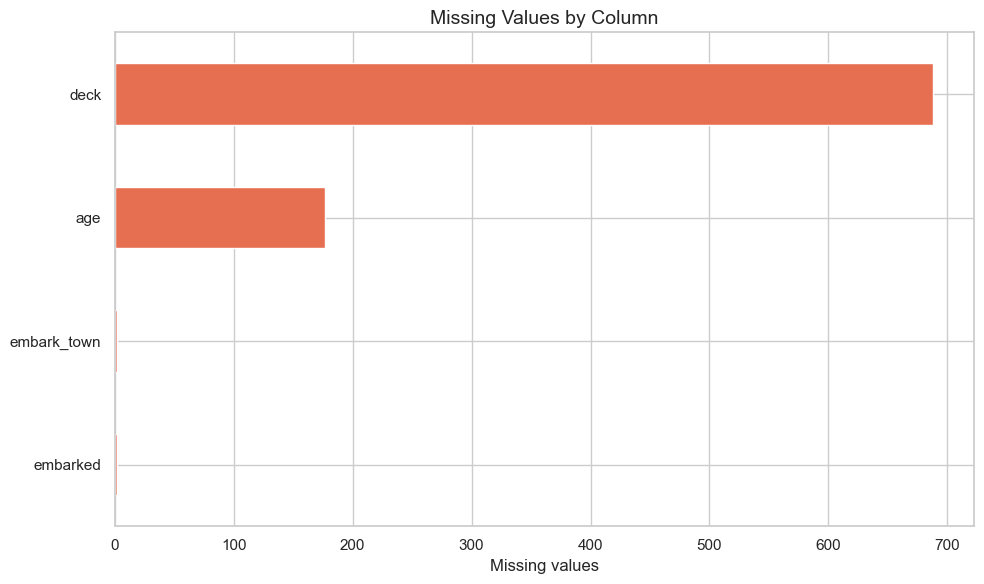

In [10]:
if missing.empty:
    print("No missing values found.")
else:
    ax = missing.sort_values(ascending=True).plot(kind="barh", color="#e76f51")
    ax.set_title("Missing Values by Column")
    ax.set_xlabel("Missing values")
    plt.tight_layout()
    plt.show()

## 8. Key Takeaways

- Compare survival by sex, class, and embarkation point.
- Inspect the impact of age and fare.
- Pay attention to missing values in `age`, `deck`, and related fields.
- Use these plots to drive feature engineering before modeling.